# Drone tracking playground: labeled-RFS trackers in heavy image clutter

**Pipeline:** simulated camera frames → blob detector → point measurements → tracker (one frame at a time, timed) → metrics + visuals

| Stage | What it is |
|---|---|
| **Scene** (`dronebench/scenario.py`) | Planar drones in a W×H pixel field of view. Each drone switches between **hover**, **cruise**, **accelerate** and **circle** modes, and drones are born and die over time. Targets are Gaussian blobs of **1–5 px FWHM** with **SNR 1–5** (peak / noise σ). Clutter is Gaussian blobs of **1–25 px**, either persistent (static or drifting) or one-frame glints. |
| **Detector** (`detector.py`) | Optional running background subtraction → high-pass → matched filter → threshold in σ → NMS → blob-size gate (LoG scale) → sub-pixel peak. |
| **Trackers** (`trackers.py`) | From this repo: **GLMB** (`jointglmb_gms_python_fast`) and **LMB** (`jointlmb_gms_python_fast`), each with **Murty** k-best or **Gibbs** sampling for data association. Not from the repo: a **GNN** Kalman tracker as a reference baseline. |
| **Metrics** (`metrics.py`) | GOSPA (localisation / missed / false), OSPA, OSPA⁽²⁾, MOTA/MOTP, IDF1, ID switches, fragmentation, MT/PT/ML, **track_recall**, **track_precision**, plus detector Pd and false alarms. |
| **Latency** | Wall-clock time per frame for the detector and for each tracker: mean, p50, p95, p99, max, and latency vs number of detections. |

The repo code is imported unchanged from its folders. The adapters supply image-plane model parameters, frame-by-frame stepping, and measurement-driven birth for the LMB (the repo LMB only has fixed birth locations). Details are in the docstring of `dronebench/trackers.py`.

In [1]:
%matplotlib inline
from dataclasses import replace
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, HTML

from dronebench import ScenarioConfig, DetectorConfig, TrackerConfig, run_experiment, sweep, SHIM_STATUS
from dronebench import viz
from dronebench.scenario import simulate
from dronebench.detector import detect_sequence
from dronebench.metrics import detector_stats

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 90
print("assignment back-ends:", SHIM_STATUS)

assignment back-ends: {'murty': 'python-shim', 'gibbs': 'python-shim'}


## 1. Parameters: edit these and re-run below

### 1a. Scene: drones, SNR and clutter
`snr` and the other range parameters take either a scalar or `(lo, hi)`; with a range, each drone draws its own value. Noise σ is 1, so amplitudes are SNRs.

In [2]:
SNR = 3.0            # <-- target SNR: 1..5, scalar or (lo, hi), e.g. (1.5, 4)

SCENARIO = ScenarioConfig(
    width=320, height=240, n_frames=80,
    bg_gradient=2.0,                 # smooth sky/ground ramp (removed by the detector high-pass)
    # drones
    n_targets_init=(3, 5),           # initial number of drones (int or range)
    birth_rate=0.03,                 # Poisson new drones / frame  -> variable number of targets
    p_death=0.004,                   # per-frame chance a drone disappears
    max_targets=10,
    spawn="edge",                    # 'edge' = fly in from the border, 'anywhere' = pop up
    stay_in_view=True,
    target_size_px=(1.0, 5.0),       # blob FWHM in px
    snr=SNR,
    snr_fluctuation=0.15,            # frame-to-frame brightness flicker
    # behaviour
    mode_probs={"hover": 0.3, "cruise": 0.25, "accel": 0.25, "circle": 0.2},
    dwell_frames=(10, 30),           # frames spent in a mode before switching
    v_max=4.0, cruise_speed=(0.8, 3.0), accel=(0.08, 0.35), circle_radius=(8, 30),
    hover_jitter=0.15, accel_noise=0.05,
    # clutter
    n_static_clutter=60,             # persistent blobs
    moving_clutter_frac=0.0,         # share of persistent blobs that drift (birds / clouds) - see sweep in §5
    clutter_speed=0.6,
    transient_clutter_rate=15.0,     # one-frame glints per frame (Poisson)
    clutter_size_px=(1.0, 25.0),     # FWHM
    clutter_snr=(0.5, 5.0),
)
SEED = 0

### 1b. Detector
The detector turns each image into the point measurements the RFS filters consume. Its settings control the detection probability vs clutter-rate trade-off the trackers see:
* `threshold`: lower values detect more weak drones but also pass more clutter.
* `bg_subtract='running'`: removes persistent clutter. The cost is that drones hovering for a long time slowly fade into the background (rate set by `bg_alpha`).
* `size_gate_sigma`: rejects blobs larger than a drone. Set it to `None` to see what large clutter does to the trackers.

In [3]:
DETECTOR = DetectorConfig(
    threshold=4.0, mf_sigma=1.0, highpass_sigma=8.0, nms_radius=3,
    size_gate_sigma=2.5,
    bg_subtract="running", bg_alpha=0.05,
    max_detections=150,
)

### 1c. Trackers
`BASE` holds the motion and measurement model shared by all trackers; each entry in the dict overrides what it needs. Key parameters:
* `P_D`, `lambda_c`: assumed detection probability and clutter rate (`'auto'` uses the mean number of detections per frame).
* `sigma_v`: CV-model acceleration noise, in px/frame². Drones that circle or accelerate need roughly 0.4–1.0.
* `p_birth`, `lambda_b`: adaptive birth. A new track can start from any measurement that no existing track explains well.
* `H_upd`: number of ranked assignments (Murty) or Gibbs samples per update. This is the main accuracy-vs-latency setting.

The Murty variants are exact k-best and scale about H_upd × tracks² per frame, so they are much slower than Gibbs in Python.

In [4]:
BASE = TrackerConfig(sigma_v=0.6, sigma_r=1.0, P_D=0.75, P_S=0.98, lambda_c="auto",
                     p_birth=0.01, lambda_b=0.2, birth_pos_std=2.0, birth_vel_std=2.5,
                     H_upd=100, H_max=200, P_G=0.999)

TRACKERS = {
    "GLMB-gibbs": replace(BASE, algo="GLMB", assoc="gibbs"),
    "GLMB-murty": replace(BASE, algo="GLMB", assoc="murty", H_upd=50),
    "LMB-gibbs":  replace(BASE, algo="LMB",  assoc="gibbs"),
    "LMB-murty":  replace(BASE, algo="LMB",  assoc="murty", H_upd=50),
    "GNN (baseline)": replace(BASE, algo="GNN", confirm_m=3, confirm_n=5, max_misses=4),
}

## 2. Look at the scene before tracking
This section runs only the simulator and detector. Green circles are true drones and red crosses are detections.

80 frames | drones seen: 6 | visible per frame: 5.0 | detector Pd=0.72, false alarms/frame=11.7, 31.5 ms/frame


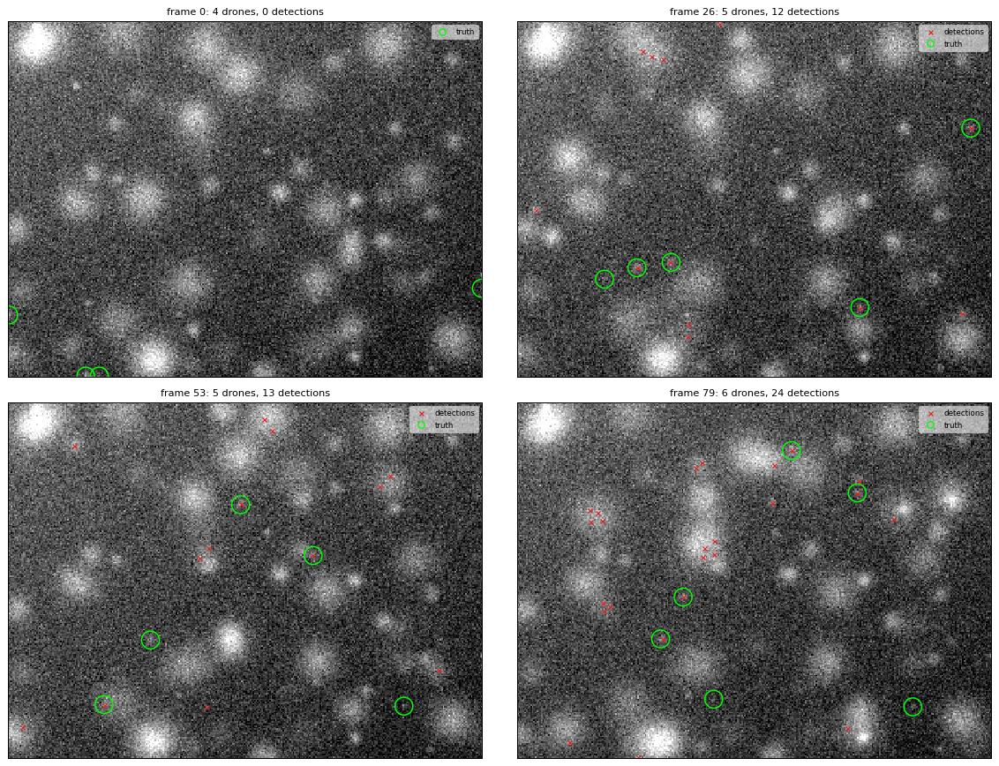

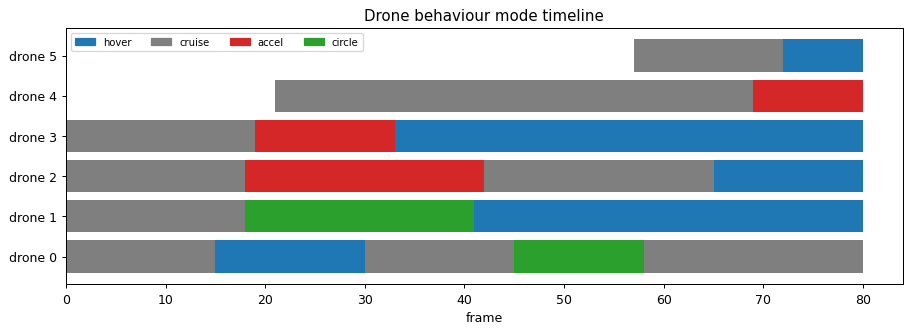

In [5]:
seq = simulate(SCENARIO, SEED)
Z, _, det_lat = detect_sequence(seq.frames, DETECTOR)
pd_k, fa_k = detector_stats([t["pos"] for t in seq.truth], Z)
print(f"{seq.K} frames | drones seen: {len({i for t in seq.truth for i in t['ids']})} | "
      f"visible per frame: {np.mean([len(t['ids']) for t in seq.truth]):.1f} | "
      f"detector Pd={np.nanmean(pd_k):.2f}, false alarms/frame={fa_k.mean():.1f}, "
      f"{det_lat.mean()*1e3:.1f} ms/frame")

class _Preview:  # minimal object for the frame drawer
    pass
pv = _Preview(); pv.seq, pv.Z, pv.runs = seq, Z, {}
viz.show_frames(pv, [0, seq.K // 3, 2 * seq.K // 3, seq.K - 1], cols=2, size=6.5); plt.show()

# behaviour modes over time
modes = {}
for k, t in enumerate(seq.truth):
    for i, m in zip(t["ids"], t["mode"]):
        modes.setdefault(i, []).append((k, m))
fig, ax = plt.subplots(figsize=(12, 0.45 * len(modes) + 1))
cmap = {"hover": "tab:blue", "cruise": "tab:gray", "accel": "tab:red", "circle": "tab:green"}
for row, (i, km) in enumerate(sorted(modes.items())):
    for k, m in km:
        ax.barh(row, 1, left=k, color=cmap[m], edgecolor="none")
ax.set_yticks(range(len(modes)), [f"drone {i}" for i in sorted(modes)]); ax.set_xlabel("frame")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=m) for m, c in cmap.items()], ncol=4, fontsize=8)
ax.set_title("Drone behaviour mode timeline"); plt.show()

## 3. Run all trackers on the same detections

In [6]:
ex = run_experiment(SCENARIO, DETECTOR, TRACKERS, seed=SEED, c=10.0, thr=5.0)
for name, r in ex.runs.items():
    if r.error:
        print(f"--- {name} failed ---\n{r.error}")

scene: 80 frames, 6 drones (avg 5.0 visible) | detector: Pd=0.72, false alarms/frame=11.7, 32.5 ms/frame | sim+detect 2.9s


GLMB-gibbs     GOSPA=  6.72  IDF1=0.88  MOTA=+0.79  track_recall=0.83  lat=   21.2 ms/frame


GLMB-murty     GOSPA=  6.56  IDF1=0.86  MOTA=+0.78  track_recall=0.83  lat=   42.2 ms/frame


LMB-gibbs      GOSPA=  7.33  IDF1=0.86  MOTA=+0.76  track_recall=0.67  lat=   20.0 ms/frame


LMB-murty      GOSPA=  6.71  IDF1=0.87  MOTA=+0.79  track_recall=0.83  lat=   57.9 ms/frame


GNN (baseline) GOSPA= 10.14  IDF1=0.76  MOTA=+0.54  track_recall=0.83  lat=    5.7 ms/frame


### 3a. Metrics table
* **GOSPA** (c=10 px, p=2, α=2) is a per-frame set error, averaged over frames; lower is better. `GOSPA_loc`, `GOSPA_missed` and `GOSPA_false` split it by error type.
* **OSPA2** is OSPA⁽²⁾, a track-level error over a sliding 10-frame window that penalises label switches and broken tracks.
* **MOTA**, **MOTP**, **IDF1**, **ID_switches** and **fragmentations** are the CLEAR-MOT and identity metrics, using a 5 px match threshold.
* **track_recall** is the share of true drones tracked for at least 80% of their visible life. **track_precision** is the share of estimated tracks (at least 5 frames long) that stay on a single drone for at least 50% of their life.
* **MT / PT / ML** count drones that are mostly tracked, partly tracked or mostly lost.
* **lat_\*_ms** are tracker latencies per frame. The detector latency is reported separately in 3d.

,GOSPA,GOSPA_loc,GOSPA_missed,GOSPA_false,OSPA2,card_err,MOTA,MOTP,IDF1,ID_switches,fragmentations,track_recall,track_precision,MT,PT,ML,n_est_tracks,n_gt_tracks,lat_mean_ms,lat_p95_ms,lat_max_ms,fps
algorithm,,,,,,,,,,,,,,,,,,,,,,
GLMB-gibbs,6.72,1.24,6.16,0.09,3.36,1.04,0.79,0.57,0.88,1,7,0.83,1.00,5,1,0,8,6,21.16,28.29,30.97,47.26
GLMB-murty,6.56,1.24,5.98,0.09,3.35,1.01,0.78,0.57,0.86,4,8,0.83,1.00,5,1,0,9,6,42.23,64.62,117.92,23.68
LMB-gibbs,7.33,1.18,6.95,0.00,3.51,1.21,0.76,0.56,0.86,1,11,0.67,1.00,4,2,0,7,6,20.02,28.12,33.26,49.94
LMB-murty,6.71,1.24,6.20,0.00,3.23,1.06,0.79,0.57,0.87,1,11,0.83,1.00,5,1,0,7,6,57.93,86.46,108.95,17.26
GNN (baseline),10.14,1.49,5.93,6.02,4.77,1.31,0.54,0.62,0.76,2,3,0.83,0.37,5,1,0,23,6,5.67,8.15,11.78,176.26


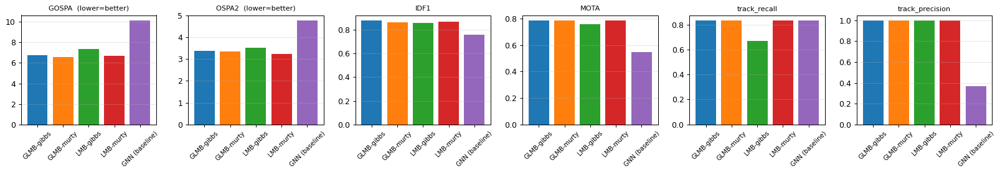

In [7]:
tab = ex.table()
show = ["GOSPA", "GOSPA_loc", "GOSPA_missed", "GOSPA_false", "OSPA2", "card_err", "MOTA", "MOTP", "IDF1",
        "ID_switches", "fragmentations", "track_recall", "track_precision", "MT", "PT", "ML",
        "n_est_tracks", "n_gt_tracks", "lat_mean_ms", "lat_p95_ms", "lat_max_ms", "fps"]
display(tab[show].style.format(precision=2)
        .highlight_min(subset=["GOSPA", "OSPA2", "card_err", "ID_switches", "lat_mean_ms"], color="#c8f7c5")
        .highlight_max(subset=["MOTA", "IDF1", "track_recall", "track_precision"], color="#c8f7c5"))
viz.plot_summary(tab); plt.show()

### 3b. Metrics over time

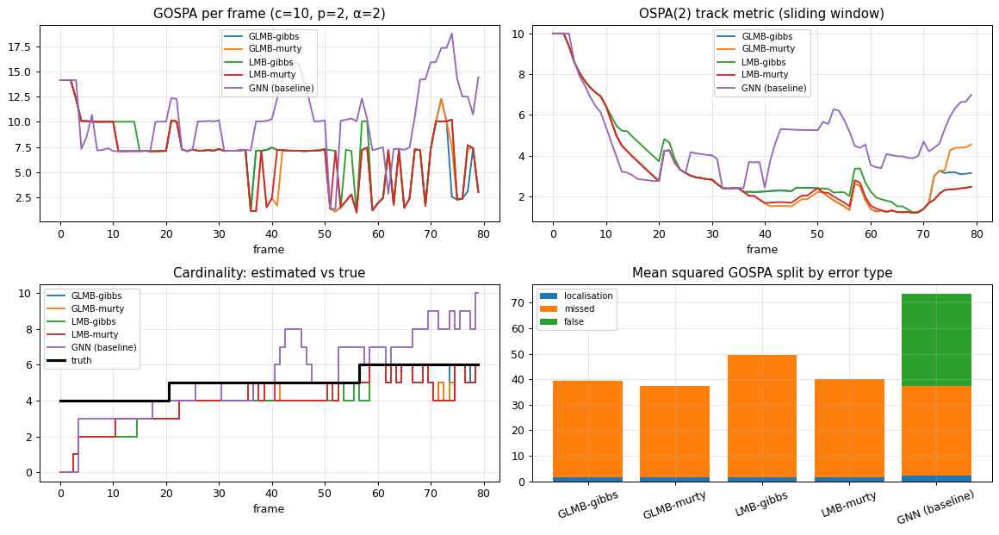

In [8]:
viz.plot_metrics(ex); plt.show()

### 3c. Visual performance
Trajectories over the whole run, followed by a frame-by-frame viewer. Use **Play** or the slider, and pick a tracker from the dropdown. Boxes are tracks, labelled by ID with a trail; green circles are the truth.

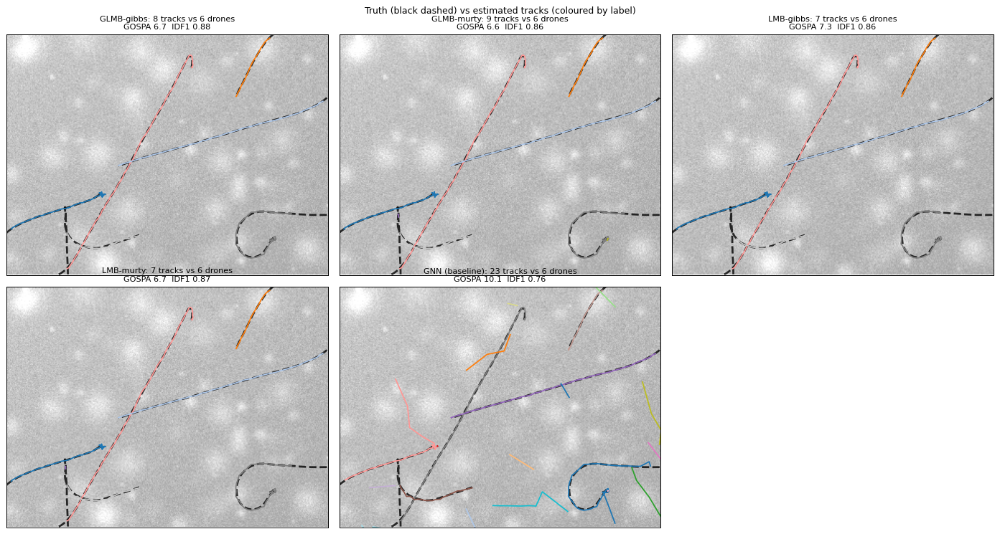

In [9]:
viz.plot_trajectories(ex); plt.show()

In [10]:
viz.frame_viewer(ex)     # interactive (needs ipywidgets; VS Code / JupyterLab render it)

In [11]:
# Animation that works without widgets; also saved as a GIF next to the notebook
ALGO_TO_ANIMATE = "GLMB-gibbs"
anim = viz.animate(ex, ALGO_TO_ANIMATE, fps=6)
viz.save_animation(anim, f"tracking_{ALGO_TO_ANIMATE}.gif", fps=6)
HTML(anim.to_jshtml())

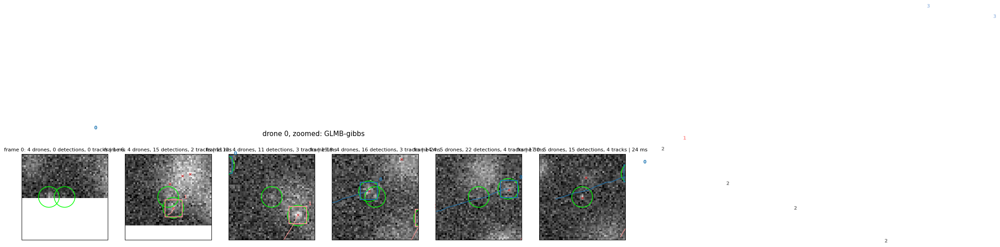

In [12]:
# Zoomed snapshot strip around one drone
drone = seq.truth[seq.K // 2]["ids"][0] if len(seq.truth[seq.K // 2]["ids"]) else None
if drone is not None:
    ks = [k for k, t in enumerate(ex.seq.truth) if drone in t["ids"]][::max(1, seq.K // 12)][:6]
    fig, axs = plt.subplots(1, len(ks), figsize=(3.2 * len(ks), 3.4))
    for ax, k in zip(np.atleast_1d(axs), ks):
        t = ex.seq.truth[k]; x, y = t["pos"][list(t["ids"]).index(drone)]
        viz.draw_frame(ax, ex, k, ALGO_TO_ANIMATE, zoom=(x, y, 25))
        ax.legend().remove()
    fig.suptitle(f"drone {drone}, zoomed: {ALGO_TO_ANIMATE}"); plt.show()

### 3d. Latency
Tracker wall-clock time per frame, how it is distributed, how it grows with the number of detections, and the filter size (number of GLMB hypotheses or LMB tracks). The dotted line is a 30 fps budget.

> The `murty` and `gibbs` assignment back-ends run in Python here (see `SHIM_STATUS` at the top), so absolute times are higher than the repo's compiled C++ builds would give. Relative comparisons and growth trends are still meaningful.

,count,mean,std,min,50%,90%,95%,99%,max
GLMB-gibbs,80.00,21.16,5.72,0.55,21.80,27.44,28.29,30.38,30.97
GLMB-murty,80.00,42.23,17.98,0.52,41.30,59.80,64.62,110.50,117.92
LMB-gibbs,80.00,20.02,5.56,0.46,20.61,25.73,28.12,31.65,33.26
LMB-murty,80.00,57.93,19.20,0.31,60.60,79.32,86.46,99.58,108.95
GNN (baseline),80.00,5.67,1.93,0.01,5.82,7.85,8.15,9.97,11.78
detector,80.00,32.47,4.05,5.01,31.88,35.81,38.81,41.86,43.98


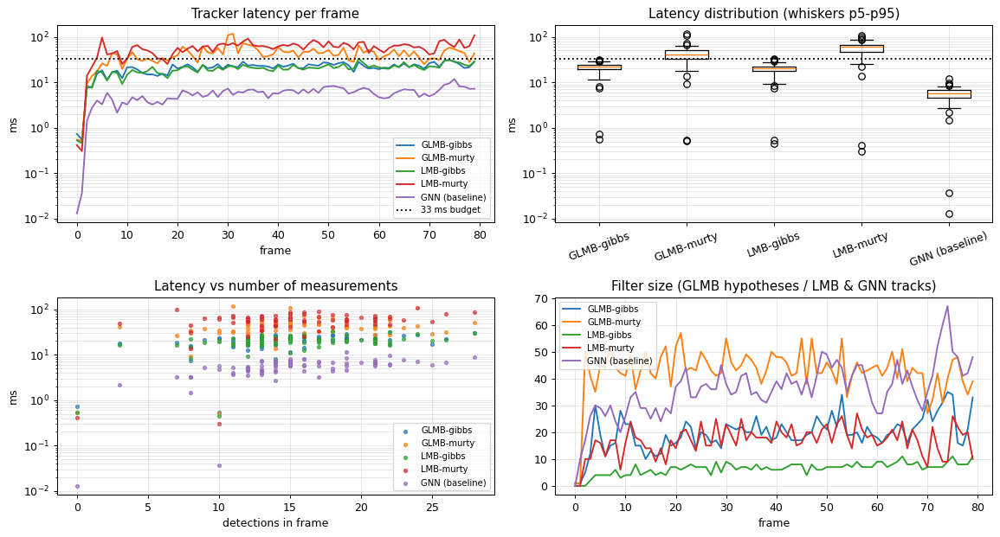

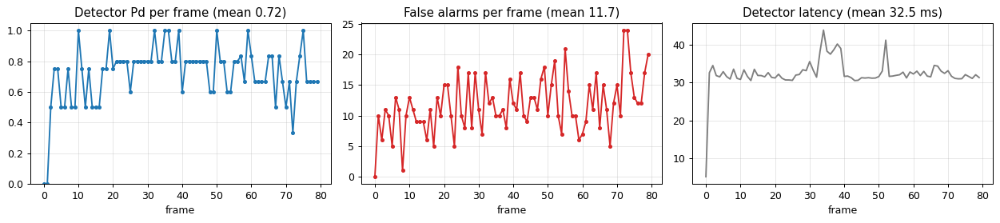

In [13]:
lat = pd.DataFrame({n: r.latency * 1e3 for n, r in ex.runs.items()})
lat["detector"] = ex.det_latency * 1e3
display(lat.describe(percentiles=[.5, .9, .95, .99]).T.style.format(precision=2))
viz.plot_latency(ex, budget_ms=33.3); plt.show()
viz.plot_detector(ex); plt.show()

## 4. Playground: change settings and re-run
Every scene, detector and tracker setting below can be changed with sliders. Press **Run** to re-run with the selected trackers; the panel shows the table, plots and frame viewer. The last run is stored in `PG["ex"]`.

In [14]:
from dronebench.ui import playground
PG = playground(replace(SCENARIO, n_frames=60), DETECTOR,
                {k: v for k, v in TRACKERS.items() if "murty" not in k})

## 5. Parameter sweeps (Monte Carlo)
`sweep(scenario, detector, trackers, "<where>.<field>", values, seeds)` changes one parameter at a time. `<where>` is `scenario`, `detector` or `tracker`. The plots show mean ± std over seeds.

Examples: `"scenario.snr"`, `"scenario.n_static_clutter"`, `"scenario.transient_clutter_rate"`, `"scenario.target_size_px"`, `"detector.threshold"`, `"detector.bg_subtract"`, `"tracker.H_upd"`, `"tracker.P_D"`, `"tracker.sigma_v"`.

The sequences are short by default so a sweep takes a few minutes. Increase `n_frames` and the number of seeds for publication-quality numbers.

[1/10] scenario.snr=1.0 seed=0


[2/10] scenario.snr=1.0 seed=1


[3/10] scenario.snr=2.0 seed=0


[4/10] scenario.snr=2.0 seed=1


[5/10] scenario.snr=3.0 seed=0


[6/10] scenario.snr=3.0 seed=1


[7/10] scenario.snr=4.0 seed=0


[8/10] scenario.snr=4.0 seed=1


[9/10] scenario.snr=5.0 seed=0


[10/10] scenario.snr=5.0 seed=1


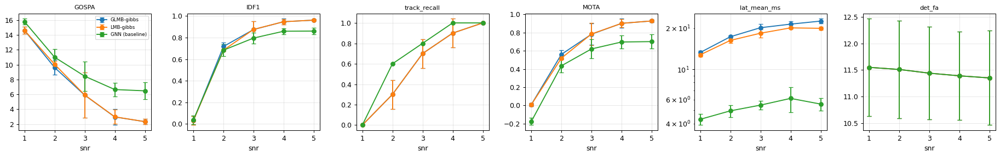

GOSPA                                IDF1                          track_recall                                MOTA                          lat_mean_ms                           \
algorithm    GLMB-gibbs GNN (baseline) LMB-gibbs GLMB-gibbs GNN (baseline) LMB-gibbs   GLMB-gibbs GNN (baseline) LMB-gibbs GLMB-gibbs GNN (baseline) LMB-gibbs  GLMB-gibbs GNN (baseline) LMB-gibbs   
scenario.snr                                                                                                                                                                                          
1.0               14.61          15.78     14.61       0.03           0.04      0.03          0.0            0.0       0.0       0.01          -0.18      0.01       13.28           4.30     12.76   
2.0                9.62          11.00     10.05       0.72           0.68      0.68          0.3            0.6       0.3       0.56           0.43      0.52       17.32           4.96     16.28   
3.0                5.90           8.45      5.92       0.88           0.80      0.88          0.7            0.8       0.7       0.78           0.62      0.78       20.17           5.46     18.38   
4.0                2.97           6.65      2.98       0.95           0.86      0.95          0.9            1.0       0.9       0.90           0.70      0.90       21.43           6.12     20.12   
5.0                2.34           6.48      2.34       0.96           0.86      0.96          1.0            1.0       1.0       0.93           0.70      0.93       22.56           5.56     19.97   

                 det_pd                              det_fa                           
algorithm    GLMB-gibbs GNN (baseline) LMB-gibbs GLMB-gibbs GNN (baseline) LMB-gibbs  
scenario.snr                                                                          
1.0                0.05           0.05      0.05      11.55          11.55     11.55  
2.0                0.46           0.46      0.46      11.51          11.51     11.51  
3.0                0.76           0.76      0.76      11.44          11.44     11.44  
4.0                0.88           0.88      0.88      11.39          11.39     11.39  
5.0                0.93           0.93      0.93      11.35          11.35     11.35

In [15]:
SWEEP_SCN = replace(SCENARIO, n_frames=50)
SWEEP_TRK = {k: v for k, v in TRACKERS.items() if "murty" not in k}

df_snr = sweep(SWEEP_SCN, DETECTOR, SWEEP_TRK, "scenario.snr", [1.0, 2.0, 3.0, 4.0, 5.0], seeds=(0, 1))
viz.plot_sweep(df_snr, "scenario.snr"); plt.show()
display(df_snr.groupby(["algorithm", "scenario.snr"])[["GOSPA", "IDF1", "track_recall", "MOTA", "lat_mean_ms", "det_pd", "det_fa"]]
        .mean().unstack(0).round(2))

[1/8] scenario.transient_clutter_rate=0 seed=0


[2/8] scenario.transient_clutter_rate=0 seed=1


[3/8] scenario.transient_clutter_rate=15 seed=0


[4/8] scenario.transient_clutter_rate=15 seed=1


[5/8] scenario.transient_clutter_rate=30 seed=0


[6/8] scenario.transient_clutter_rate=30 seed=1


[7/8] scenario.transient_clutter_rate=60 seed=0


[8/8] scenario.transient_clutter_rate=60 seed=1


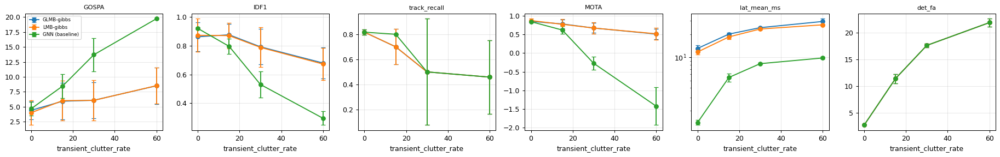

In [16]:
# Clutter density sweep at a fixed SNR
df_cl = sweep(replace(SWEEP_SCN, snr=3.0), DETECTOR, SWEEP_TRK, "scenario.transient_clutter_rate",
              [0, 15, 30, 60], seeds=(0, 1))
viz.plot_sweep(df_cl, "scenario.transient_clutter_rate"); plt.show()

[1/6] scenario.moving_clutter_frac=0.0 seed=0


[2/6] scenario.moving_clutter_frac=0.0 seed=1


[3/6] scenario.moving_clutter_frac=0.1 seed=0


[4/6] scenario.moving_clutter_frac=0.1 seed=1


[5/6] scenario.moving_clutter_frac=0.25 seed=0


[6/6] scenario.moving_clutter_frac=0.25 seed=1


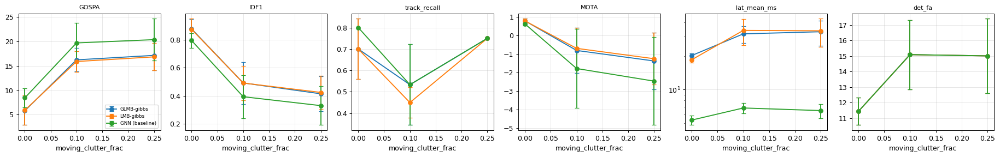

In [17]:
# Drifting clutter (birds / clouds): kinematically identical to slow drones for a point tracker
df_mv = sweep(SWEEP_SCN, DETECTOR, SWEEP_TRK, "scenario.moving_clutter_frac", [0.0, 0.1, 0.25], seeds=(0, 1))
viz.plot_sweep(df_mv, "scenario.moving_clutter_frac"); plt.show()

[1/4] tracker.H_upd=10 seed=0


[2/4] tracker.H_upd=50 seed=0


[3/4] tracker.H_upd=100 seed=0


[4/4] tracker.H_upd=300 seed=0


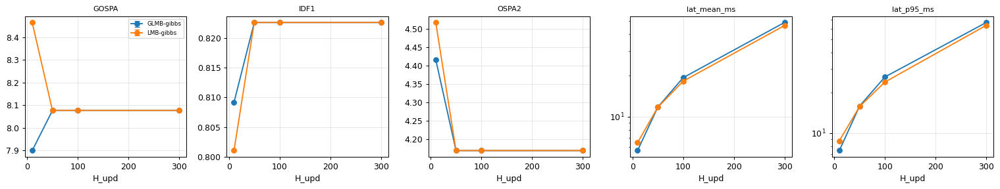

In [18]:
# Accuracy vs latency: number of hypotheses / samples (GLMB and LMB with Gibbs)
df_h = sweep(SWEEP_SCN, DETECTOR, {k: v for k, v in SWEEP_TRK.items() if "gibbs" in k},
             "tracker.H_upd", [10, 50, 100, 300], seeds=(0,))
viz.plot_sweep(df_h, "tracker.H_upd", metrics=("GOSPA", "IDF1", "OSPA2", "lat_mean_ms", "lat_p95_ms")); plt.show()

## Notes
* **Shims.** The repo's `*_fast` trackers import two compiled packages: `murty` (github.com/JohnPekl/murty) and `gibbs` (`cpp_gibbs`, which needs MSVC and Eigen). If they are importable they are used as-is; otherwise `dronebench/shims.py` provides Python implementations of the same algorithms. The Murty solver is checked against brute force.
* **Estimator.** Estimates are extracted each frame (MAP cardinality, then the best hypothesis with that cardinality), so results are online and latency is per frame. The repo GLMB's `extract_estimates_recursive` is a smoother that replays the full history every frame; it is not used here.
* **Clutter that looks like drones.** Persistent small blobs look exactly like hovering drones, and drifting ones look like slow fliers. No point-measurement tracker can separate them without appearance cues. Background subtraction removes the static ones, which is why it is on by default. Drifting clutter is off by default (`moving_clutter_frac=0`) because even 10% drifting blobs produce persistent false tracks for every tracker here; the sweep in §5 shows the effect.
* **Adding another tracker.** Write a class with `step(Z) -> (ids, positions[N,2])` and `n_hyp()`, register it in `trackers.make_tracker`, and give it a `TrackerConfig.algo` name.